# Figure 4A–D: formal ico5 K=15, registration-QC-passing cohort (n=320)

The original 325-subject frozen results are retained separately. Five visually confirmed T1–DWI registration failures (D0128, D0163, D0248, D0296, D0388) are removed. This notebook reads newly reaggregated cached subject-level results. Original sampling, subject fits and null realizations are unchanged; cohort summaries, bootstrap confidence intervals and reliability are recalculated.

Active manifest: `manifests/figure4_registration_qc_pass_320_subjects.csv`. Figure 5 remains the same 196 CN participants.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure4/outputs/registration_qc_pass_320')
MANIFEST = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/manifests/figure4_registration_qc_pass_320_subjects.csv')
subjects = pd.read_csv(MANIFEST).subject_id
assert subjects.nunique() == len(subjects) == 320
print(f'Active Figure 4 cohort: {len(subjects)} participants')


Active Figure 4 cohort: 320 participants


## Figure 4A: profile-shape dissimilarity and relative MAE

Official ico5 anchors; within-DK candidates; at most 15 pairs per anchor × 2-mm bin. Pair → anchor-bin median → bilateral subject median → cohort median/IQR. Distances use fsaverage white-surface mesh-edge geodesics. 21 depths, pial → white.

 distance_bin_index distance_bin     pair_type  n_subjects  anchor_count_total  pair_count_total  profile_dissimilarity_median  profile_dissimilarity_q25  profile_dissimilarity_q75  profile_mae_median  profile_mae_q25  profile_mae_q75  profile_rmse_median  profile_rmse_q25  profile_rmse_q75  geodesic_distance_mm_median  geodesic_distance_mm_q25  geodesic_distance_mm_q75
                  0          0-2 within_region         320             5918088          87561690                      0.052209                   0.043055                   0.064304            0.000076         0.000069         0.000083             0.000093          0.000085          0.000101                     1.422339                  1.422076                  1.422563
                  1          2-4 within_region         320             5918667          88224193                      0.097733                   0.081001                   0.119874            0.000113         0.000102         0.000124             0.00013

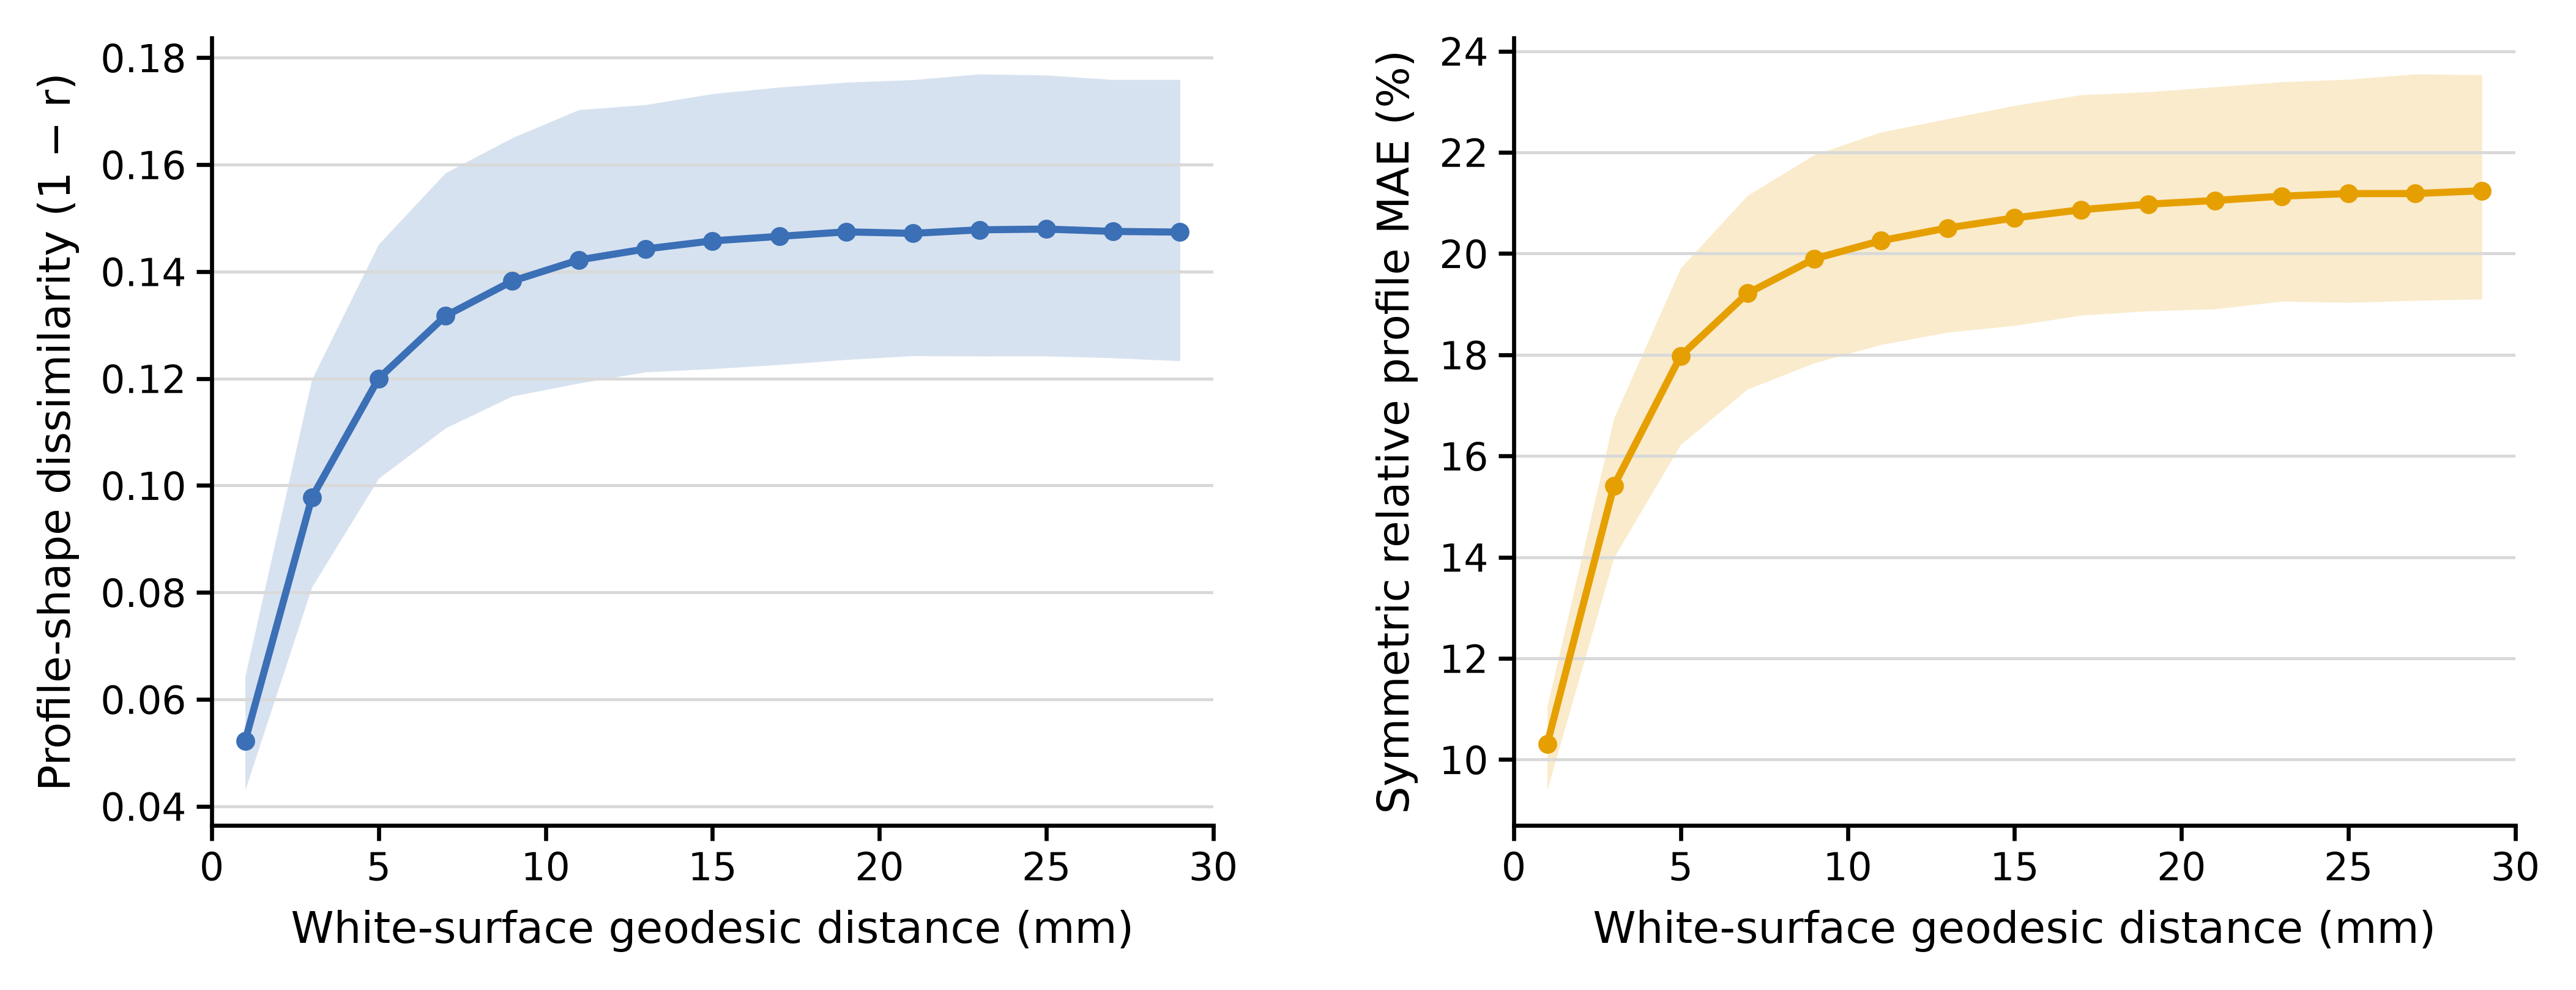

In [2]:
PART = ROOT / 'real/cohort'
display(pd.read_csv(PART / 'figure4A_ico5_k15_real_group_summary.csv'))
display(Image(filename=str(PART / 'Figure4A_ico5_K15_with_relative_MAE.png')))


### Additional Figure 4A: sampling scales annotated on the original curves

The original unannotated Figure 4A above is retained. This additional view uses the same source tables, 2-mm bin centers, two metrics, and group median/IQR display. Colored markers locate the pooled median nearest-neighbor white-surface geodesic spacing of the retained ico3, ico4, and ico5 centers.

Nearest-neighbor spacing is calculated across retained template centers pooled over both hemispheres. The variance is the sample variance ($ddof=1$), reported in mm$^2$; equivalently, it is `sd_nn_mm ** 2`. These are properties of the template sampling geometry and therefore do not vary across participants.

| Scale | Retained centers | Mean (mm) | Median [IQR] (mm) | SD (mm) | Variance (mm$^2$) |
|---|---:|---:|---:|---:|---:|
| ico3 | 1,175 | 8.618 | 8.513 [7.585–9.576] | 1.452 | 2.107 |
| ico4 | 4,687 | 4.275 | 4.235 [3.770–4.764] | 0.754 | 0.568 |
| ico5 | 18,742 | 2.142 | 2.121 [1.869–2.397] | 0.400 | 0.160 |

Marker heights are **linearly interpolated on the binned group-median curves for illustration**; they are not additional measurements or prediction results. Spacing describes template sampling geometry, not participant variability. The plotting cell exports PNG, PDF, SVG, and annotation coordinates.


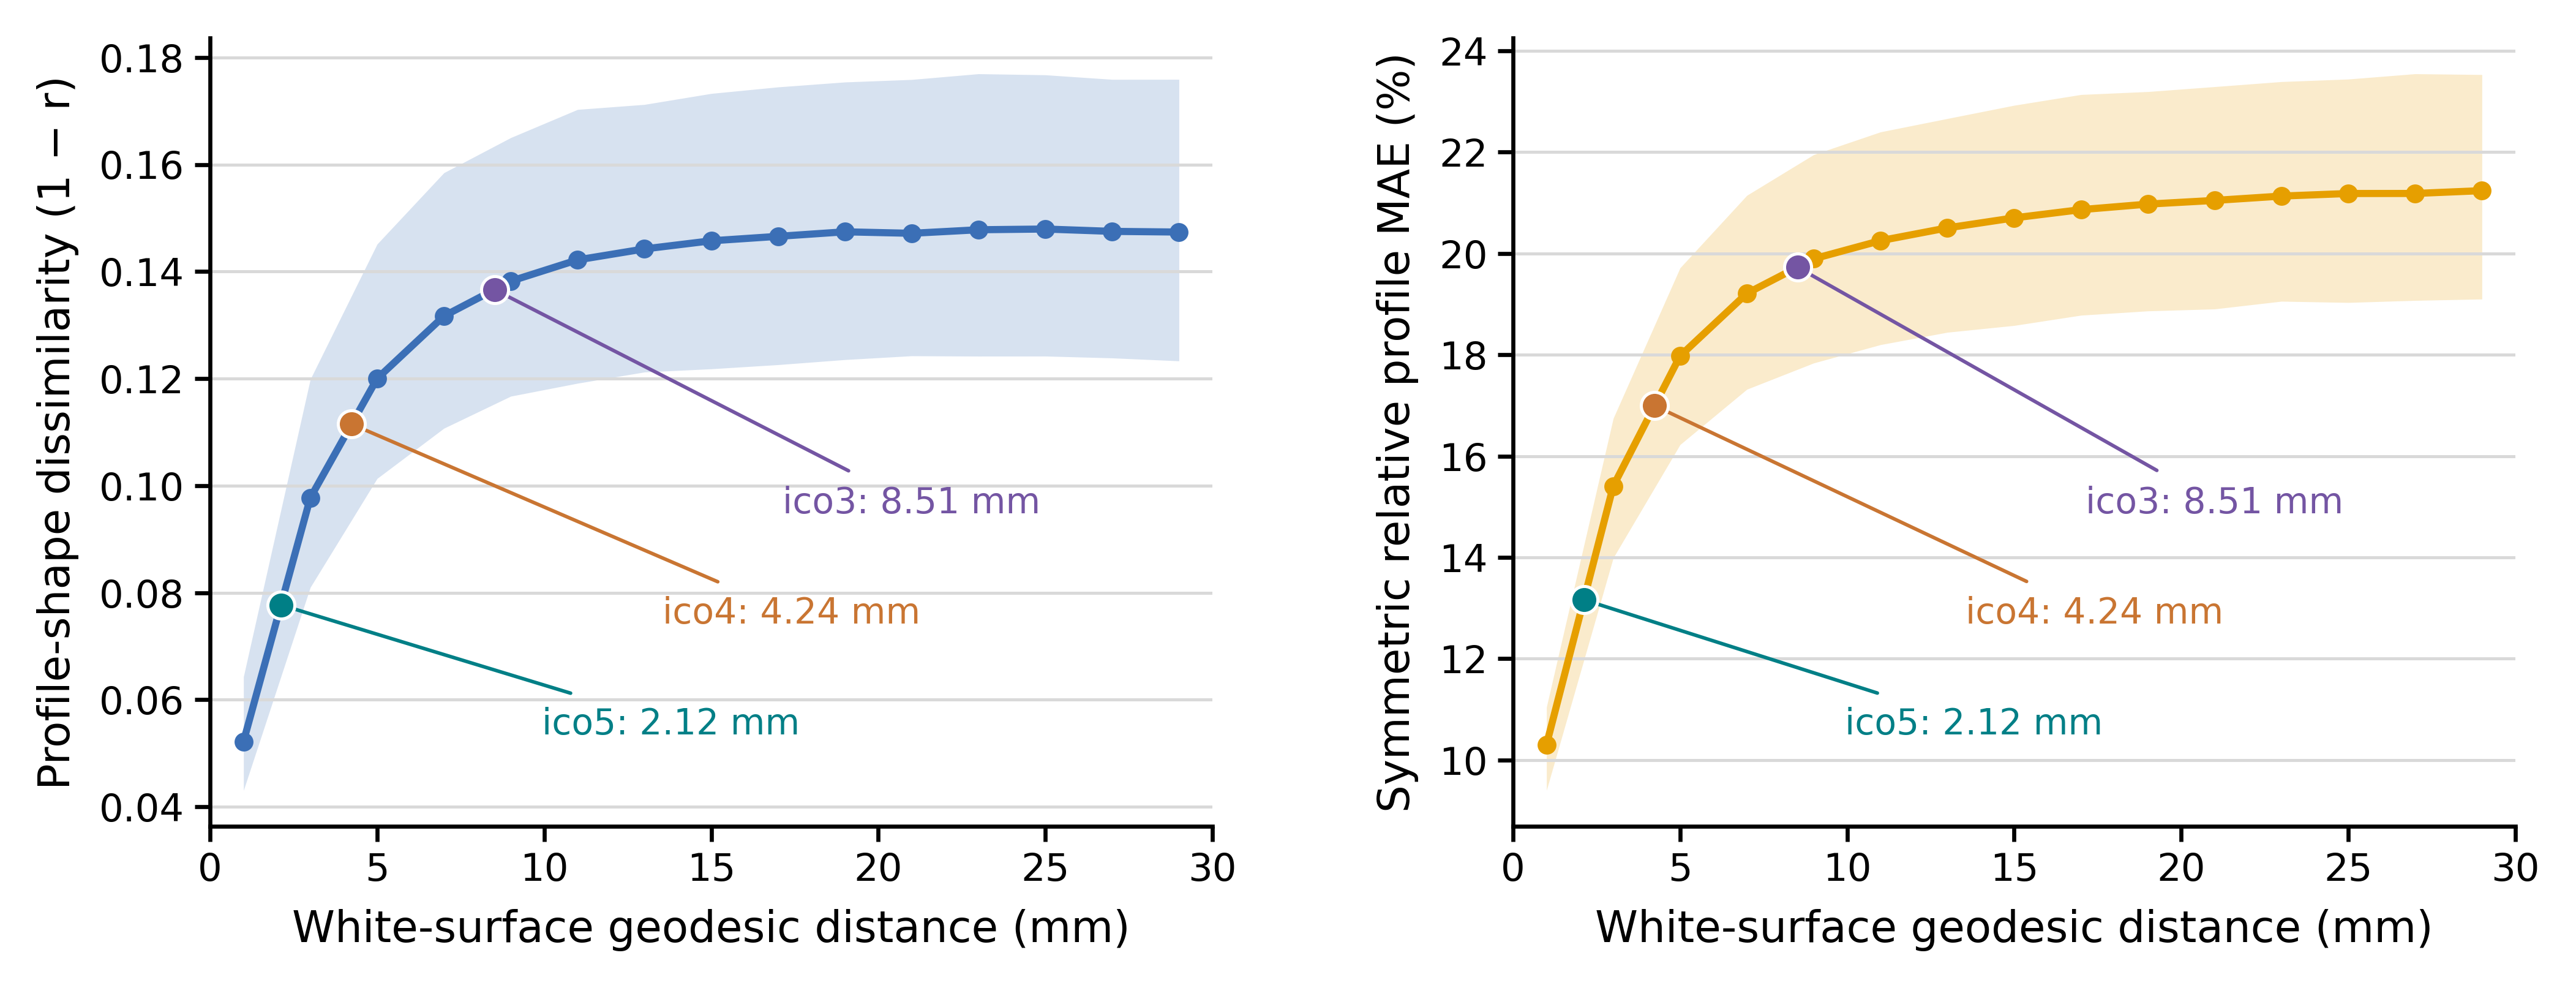

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import sys

# Same data, bin centers, metrics, and publication style as the original Figure 4A.
repo_root = next(p for p in ROOT.parents if (p / "qc/publication_style.py").exists())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, set_publication_style, style_axes,
)
set_publication_style()
real = pd.read_csv(ROOT / "real/cohort/figure4A_ico5_k15_real_group_summary.csv").sort_values("distance_bin_index")
relative = pd.read_csv(ROOT / "relative_mae/cohort/figure4_relative_mae_group_summary.csv").sort_values("distance_bin_index")
spacing = pd.read_csv(repo_root / "analysis_results/figure5/outputs/spatial_resolution/ico_nearest_neighbor_summary.csv")
spacing = spacing.loc[spacing.hemisphere.eq("bilateral_pooled")].set_index("level")
spacing["variance_nn_mm2"] = spacing["sd_nn_mm"].pow(2)
assert real.distance_bin_index.tolist() == relative.distance_bin_index.tolist()
assert real.n_subjects.eq(len(subjects)).all()
x = real.distance_bin_index.to_numpy(dtype=float) * 2 + 1
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH_IN, 2.75), sharex=True)
specs = [
    (real.profile_dissimilarity_median, real.profile_dissimilarity_q25,
     real.profile_dissimilarity_q75, PALETTE["blue"], "Profile-shape dissimilarity (1 − r)"),
    (relative["median"], relative.q25, relative.q75,
     PALETTE["orange"], "Symmetric relative profile MAE (%)"),
]
marker_colors = {"ico5": "#007F86", "ico4": "#C97532", "ico3": "#7455A3"}
annotation_rows = []
for panel, (axis, (median, q25, q75, color, ylabel)) in enumerate(zip(axes, specs)):
    axis.plot(x, median, color=color, linewidth=1.4, marker="o", markersize=2.7)
    axis.fill_between(x, q25, q75, color=color, alpha=0.2, linewidth=0)
    for index, level in enumerate(["ico5", "ico4", "ico3"]):
        distance = float(spacing.loc[level, "median_nn_mm"])
        value = float(np.interp(distance, x, median))
        marker_color = marker_colors[level]
        axis.scatter(distance, value, s=28, color=marker_color,
                     edgecolors="white", linewidths=0.6, zorder=5)
        axis.annotate(
            f"{level}: {distance:.2f} mm", xy=(distance, value),
            xytext=(0.46 + 0.12 * index, 0.13 + 0.14 * index),
            textcoords="axes fraction", ha="center", va="center",
            fontsize=7, color=marker_color,
            arrowprops={"arrowstyle": "-", "color": marker_color, "lw": 0.7},
        )
        annotation_rows.append({"panel": panel + 1, "representation": level,
                                "spacing_median_mm": distance,
                                "spacing_sd_mm": float(spacing.loc[level, "sd_nn_mm"]),
                                "spacing_variance_mm2": float(spacing.loc[level, "variance_nn_mm2"]),
                                "interpolated_curve_value": value})
    axis.set(xlabel="White-surface geodesic distance (mm)", ylabel=ylabel,
             xlim=(0, 30), xticks=np.arange(0, 31, 5))
    style_axes(axis, grid=True)
fig.subplots_adjust(left=0.10, right=0.985, bottom=0.20, top=0.98, wspace=0.30)
output_stem = ROOT / "real/cohort/Figure4A_ico5_K15_with_sampling_scales"
for extension in ("png", "pdf", "svg"):
    fig.savefig(output_stem.with_suffix("." + extension), dpi=600,
                bbox_inches="tight", facecolor="white")
plt.close(fig)
annotation_table = pd.DataFrame(annotation_rows)
annotation_table.to_csv(output_stem.with_name(output_stem.name + "_annotations.csv"), index=False)
display(Image(filename=str(output_stem.with_suffix(".png"))))


## Figure 4B: seed-fixed acquisition-and-sampling null

FWHM=0 mm; 100 existing independent realizations per retained participant. Local excess uses the 20–30-mm reference. Residual AUC is not a pure physiological estimate.

 psf_fwhm_mm  n_subjects  bootstrap_replicates  bootstrap_seed  auc_residual_local_excess_0_10_mm_median  auc_residual_local_excess_0_10_mm_q25  auc_residual_local_excess_0_10_mm_q75  auc_residual_local_excess_0_10_mm_bootstrap_ci_low  auc_residual_local_excess_0_10_mm_bootstrap_ci_high  auc_residual_local_excess_0_10_mm_positive_fraction  mean_residual_local_excess_0_10_median  mean_residual_local_excess_0_10_q25  mean_residual_local_excess_0_10_q75  mean_residual_local_excess_0_10_bootstrap_ci_low  mean_residual_local_excess_0_10_bootstrap_ci_high  mean_residual_local_excess_0_10_positive_fraction
         0.0         320                 10000        20261020                                  0.355401                               0.304949                               0.428382                                            0.347815                                             0.368329                                                  1.0                                 0.03554             

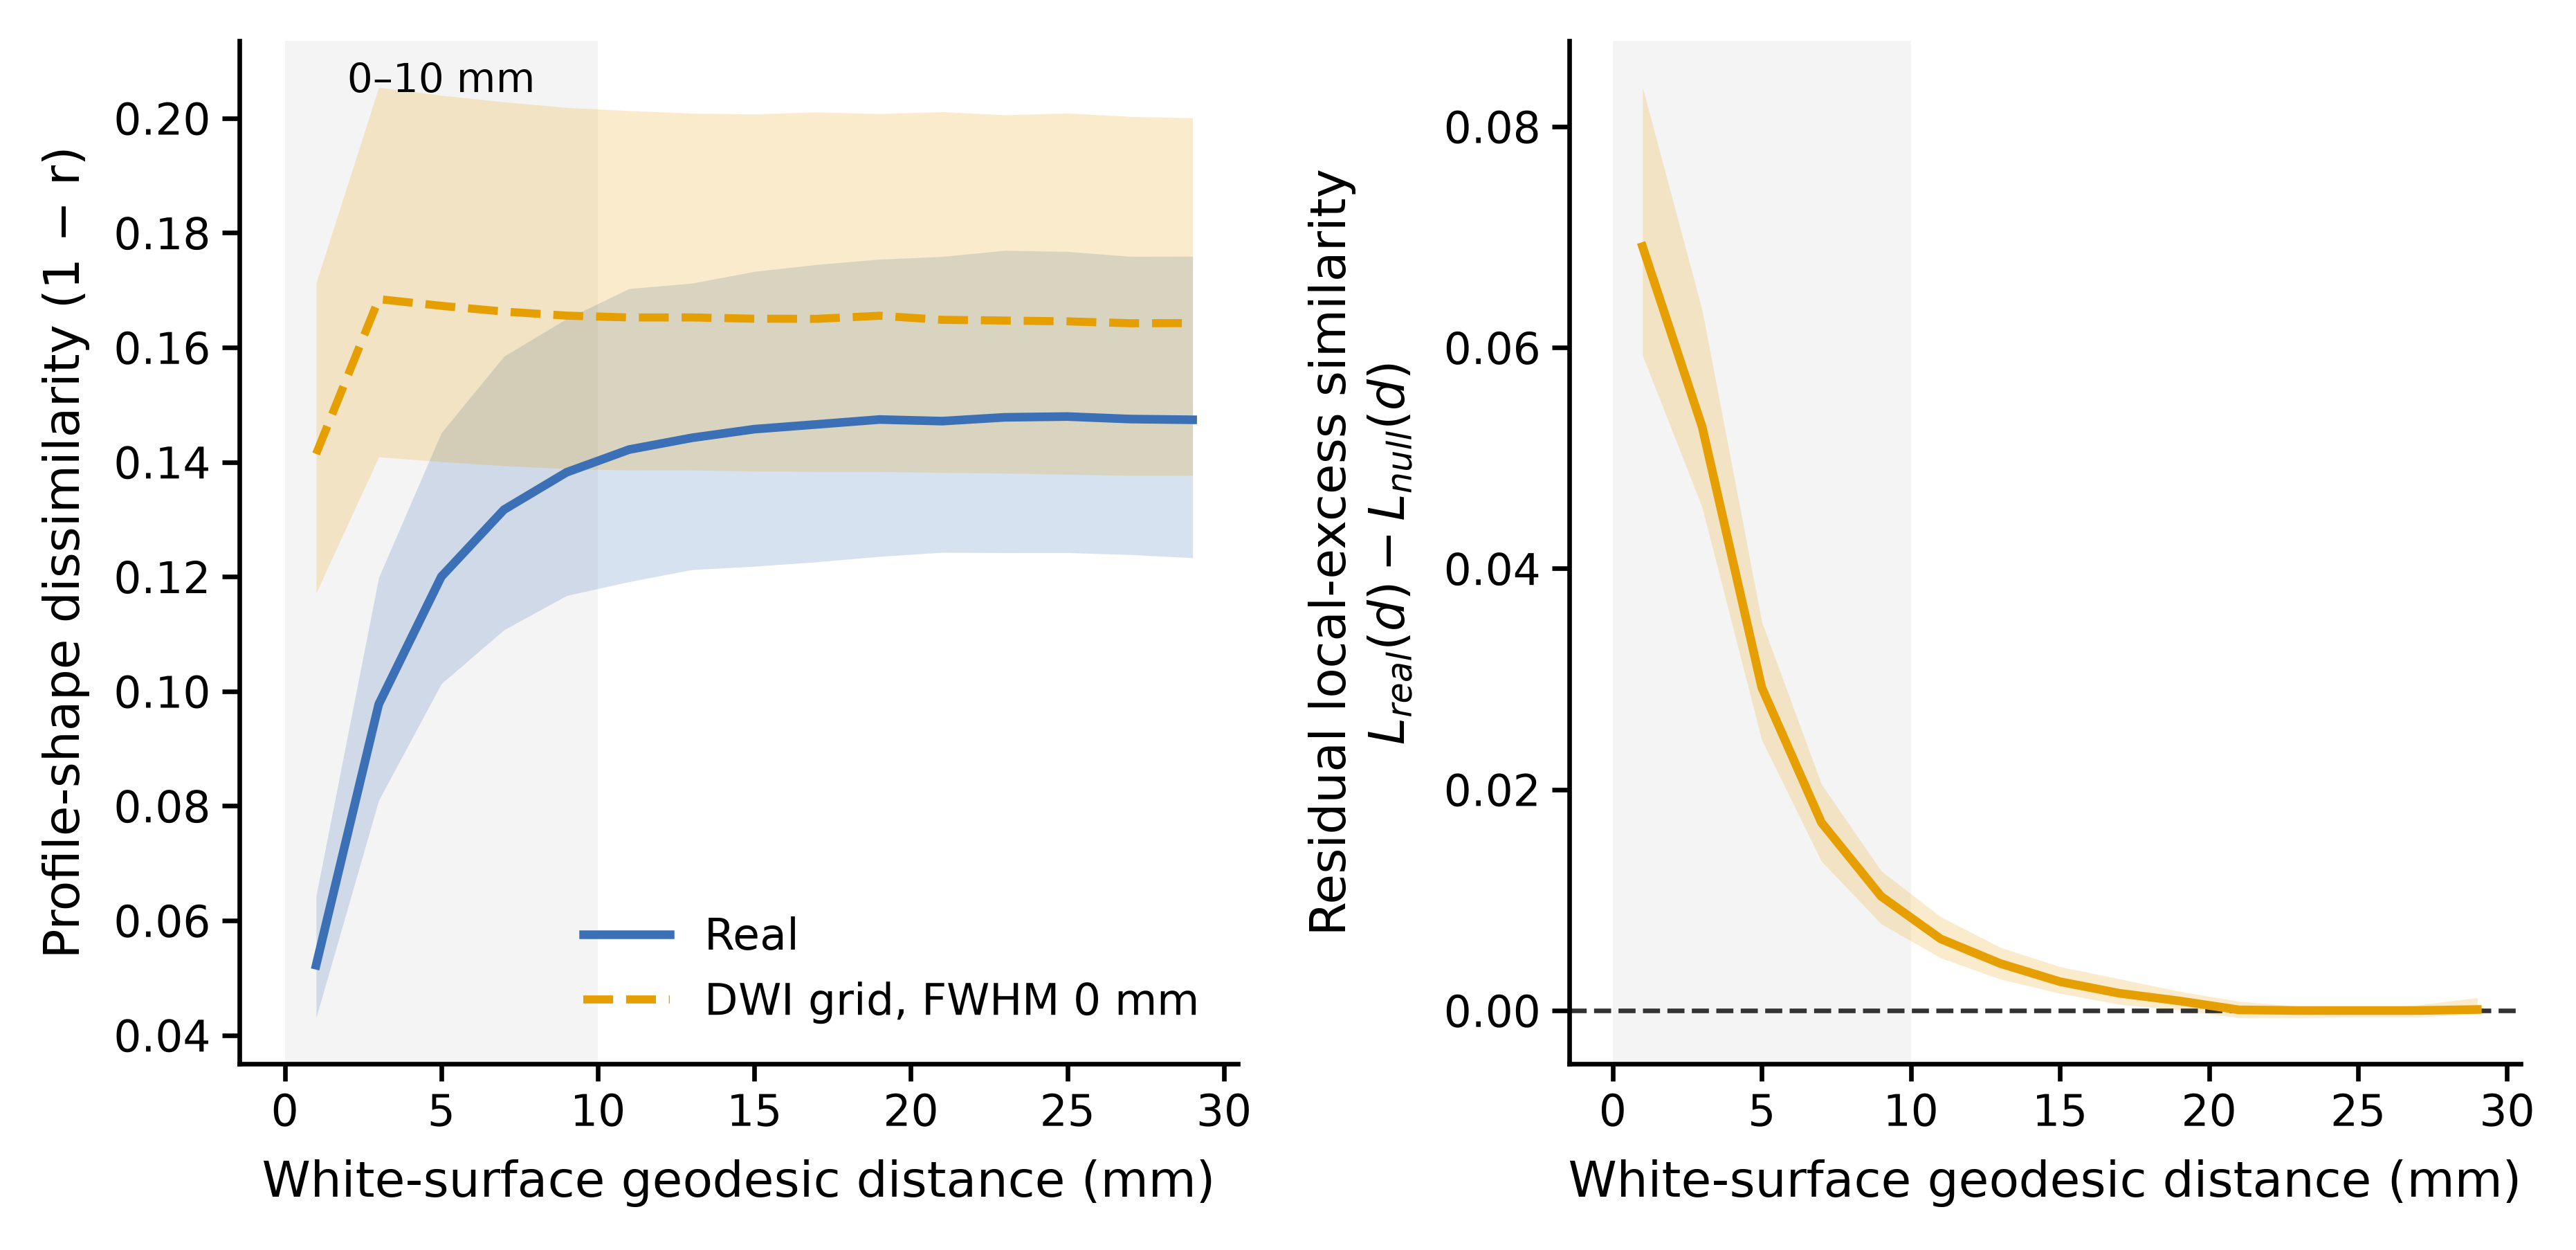

In [3]:
PART = ROOT / 'acquisition_null_fwhm0_seedfix/cohort'
display(pd.read_csv(PART / 'figure4B_local_excess_auc_group_summary.csv'))
display(Image(filename=str(PART / 'Figure4B_ico5_K15_formal_main.png')))


## Figure 4C: correlation length and fixed anchor split-half stability

D(d)=D∞−A exp(−d/λ). No refitting is required after subject exclusions. Group distribution and split-half statistics are recomputed on retained participants. This is not scan-rescan reliability.

 n_subjects  lambda_median_mm  lambda_q25_mm  lambda_q75_mm  d_infinity_median  amplitude_median  r2_median
        320          2.867548       2.681028       3.042178           0.147127          0.151458   0.996657

 n_subjects_total  n_paired_acceptable  pearson_r  spearman_rho  icc_two_way_single  median_absolute_difference_mm  n_failed_or_unacceptable_subjects
              320                  320   0.894956      0.855332             0.89494                       0.103166                                  0

   fit_scope  n_fits  n_success  n_acceptable  n_boundary  median_r2  median_residual_rmse
fixed_half_1     320        320           320           0   0.995922              0.001639
fixed_half_2     320        320           320           0   0.995027              0.001807
        full     320        320           320           0   0.996657              0.001483

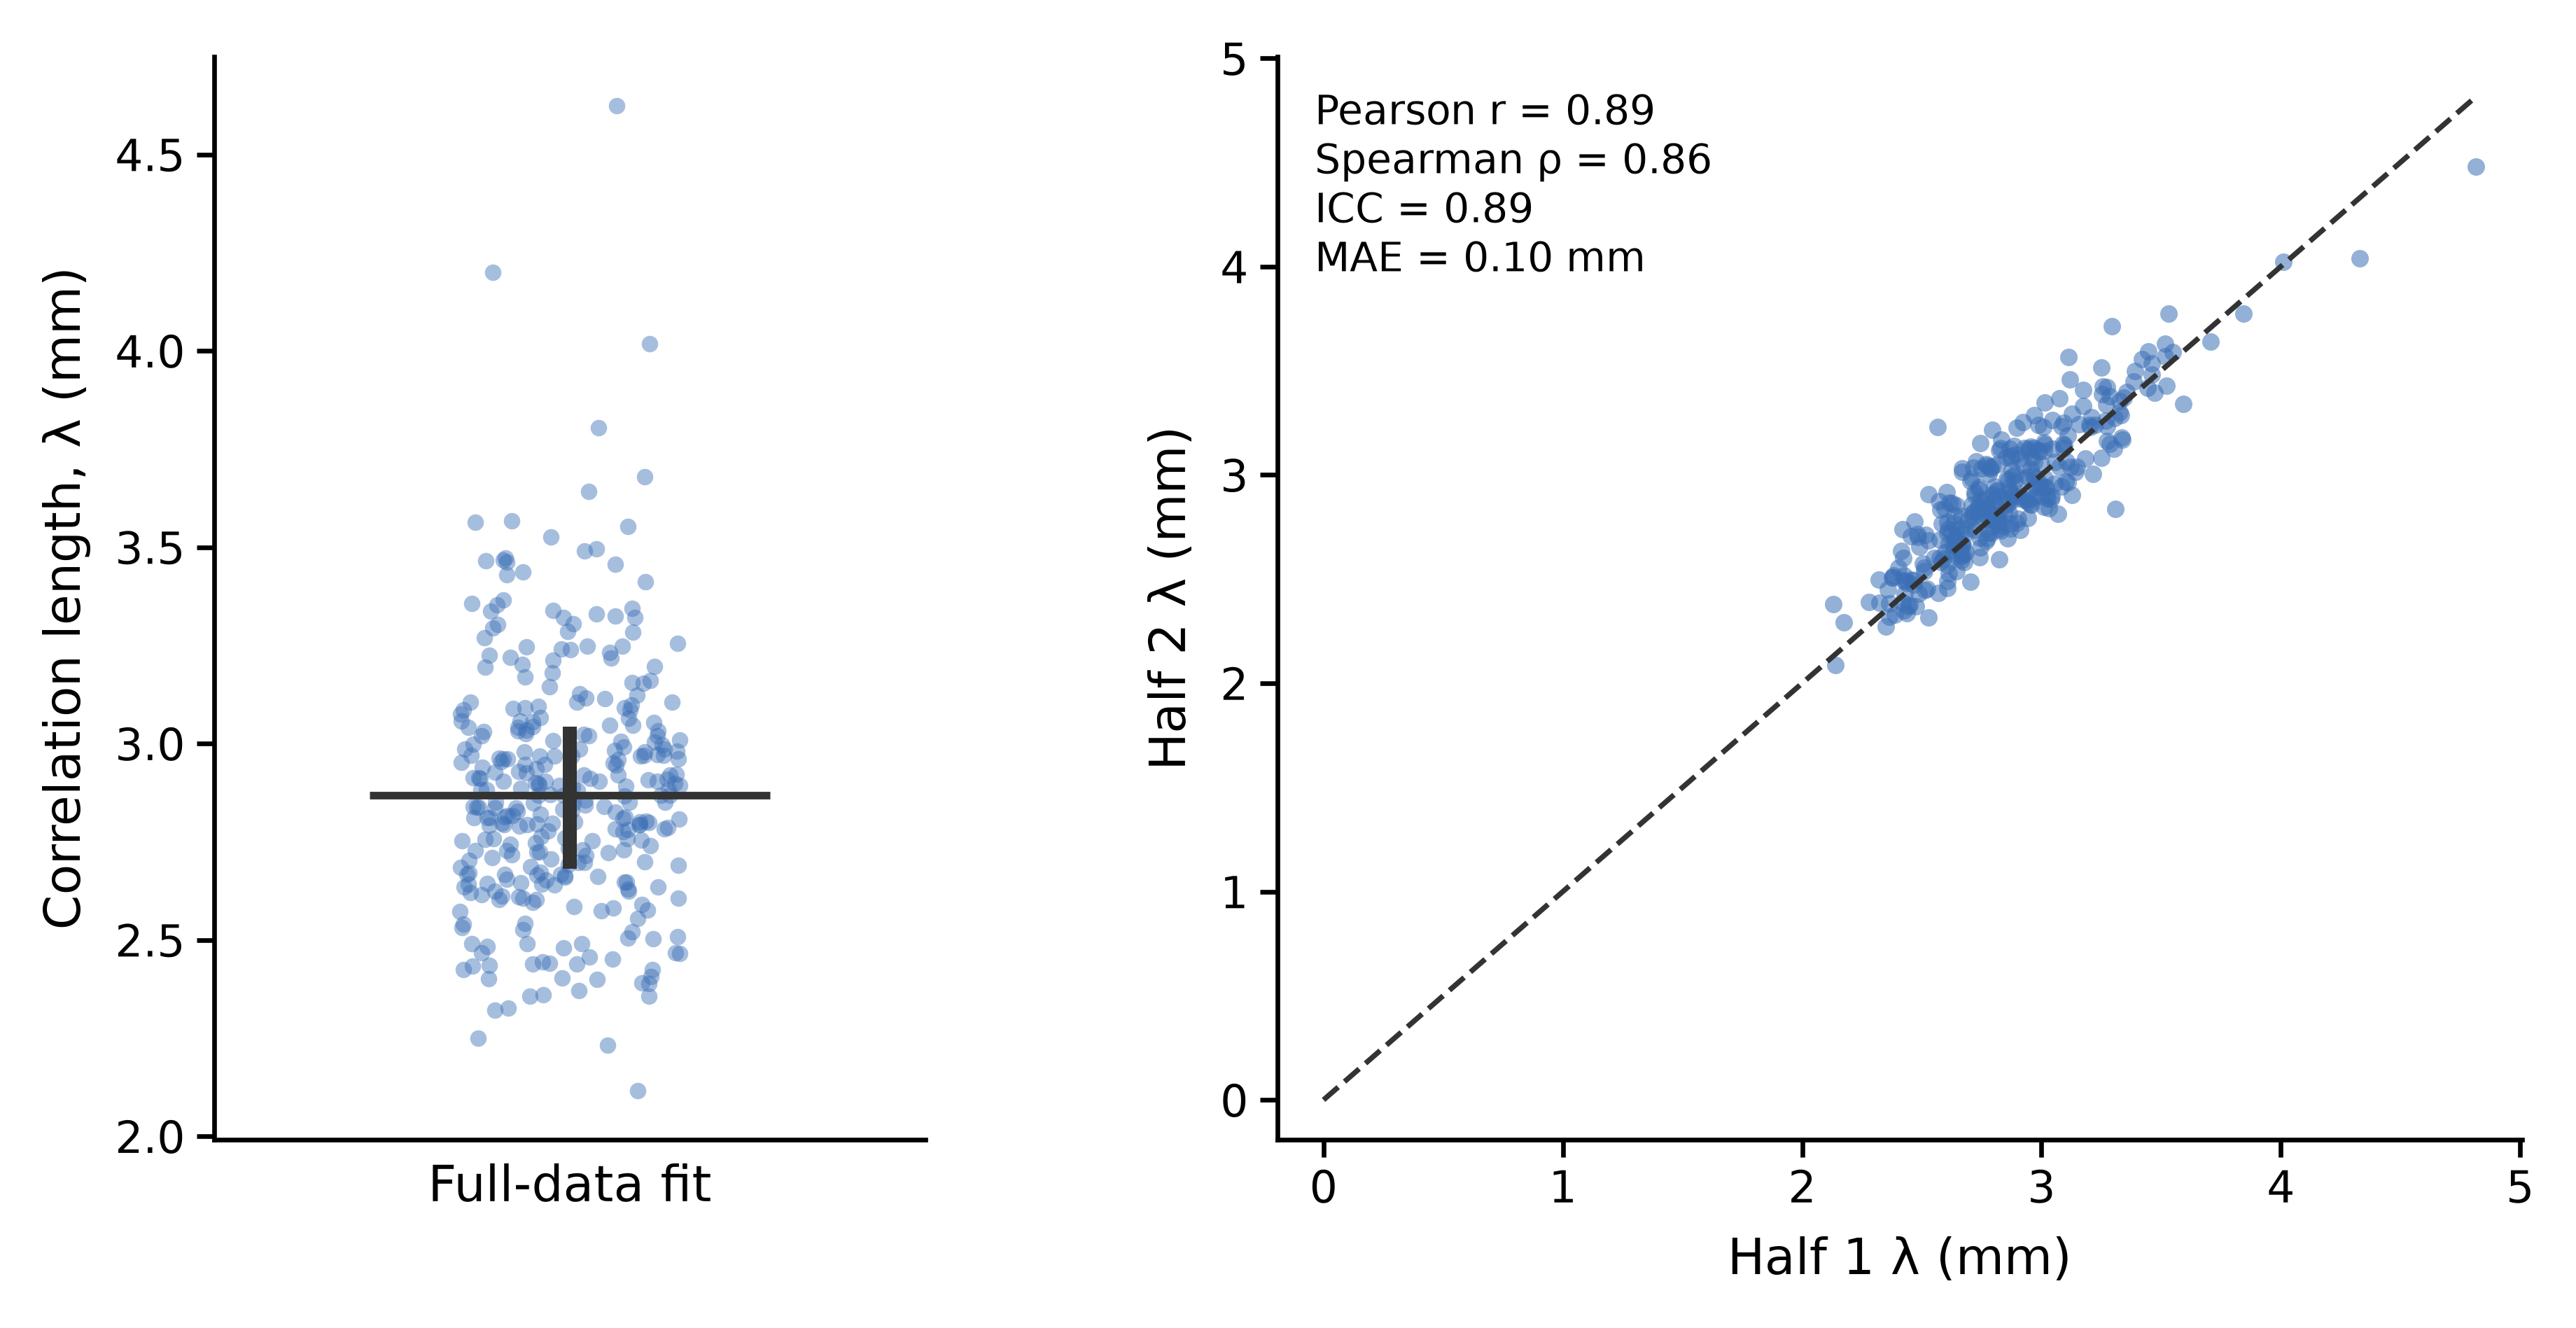

In [4]:
PART = ROOT / 'correlation_length/cohort'
display(pd.read_csv(PART / 'figure4C_full_fit_summary.csv'))
display(pd.read_csv(PART / 'figure4C_fixed_split_reliability.csv'))
display(pd.read_csv(PART / 'figure4C_fit_qc_summary.csv'))
display(Image(filename=str(PART / 'Figure4C_ico5_K15_correlation_length.png')))


## Figure 4D: matched within/across-DK boundary effect

Same-anchor one-to-one distance matching, caliper 0.1 mm. Effect ΔD=Dacross−Dwithin. Matched-pair mean → anchor-bin mean → bilateral subject-region-bin mean → equal-region subject-bin mean. This design does not support a consistent positive DK-boundary shape effect.

 n_subjects  median_mean_delta_d_0_10  q25_mean_delta_d_0_10  q75_mean_delta_d_0_10  bootstrap_ci95_low  bootstrap_ci95_high  positive_subject_count  positive_subject_fraction  bootstrap_seed  bootstrap_iterations
        320                 -0.002416              -0.006011                 0.0014           -0.003034            -0.001664                     111                   0.346875        20261027                 10000

 distance_bin_index distance_bin  n_subjects  delta_d_median  delta_d_q25  delta_d_q75  d_within_median  d_across_median  delta_profile_mae_median  region_count_median_subject  anchor_count_median_subject  match_count_median_subject
                  0          0-2         320        0.002406    -0.003325     0.006687         0.269027         0.270824              1.624319e-06                         34.0                       2910.0                     17589.5
                  1          2-4         320       -0.000307    -0.004506     0.004129         0.373983         0.371683              1.732449e-06                         34.0                       5974.0                     70300.0
                  2          4-6         320       -0.002189    -0.006937     0.002923         0.423289         0.417147              1.640494e-06                         34.0                       8601.0                    113946.0
                  3          6-8         320       -0.004526    -0.0

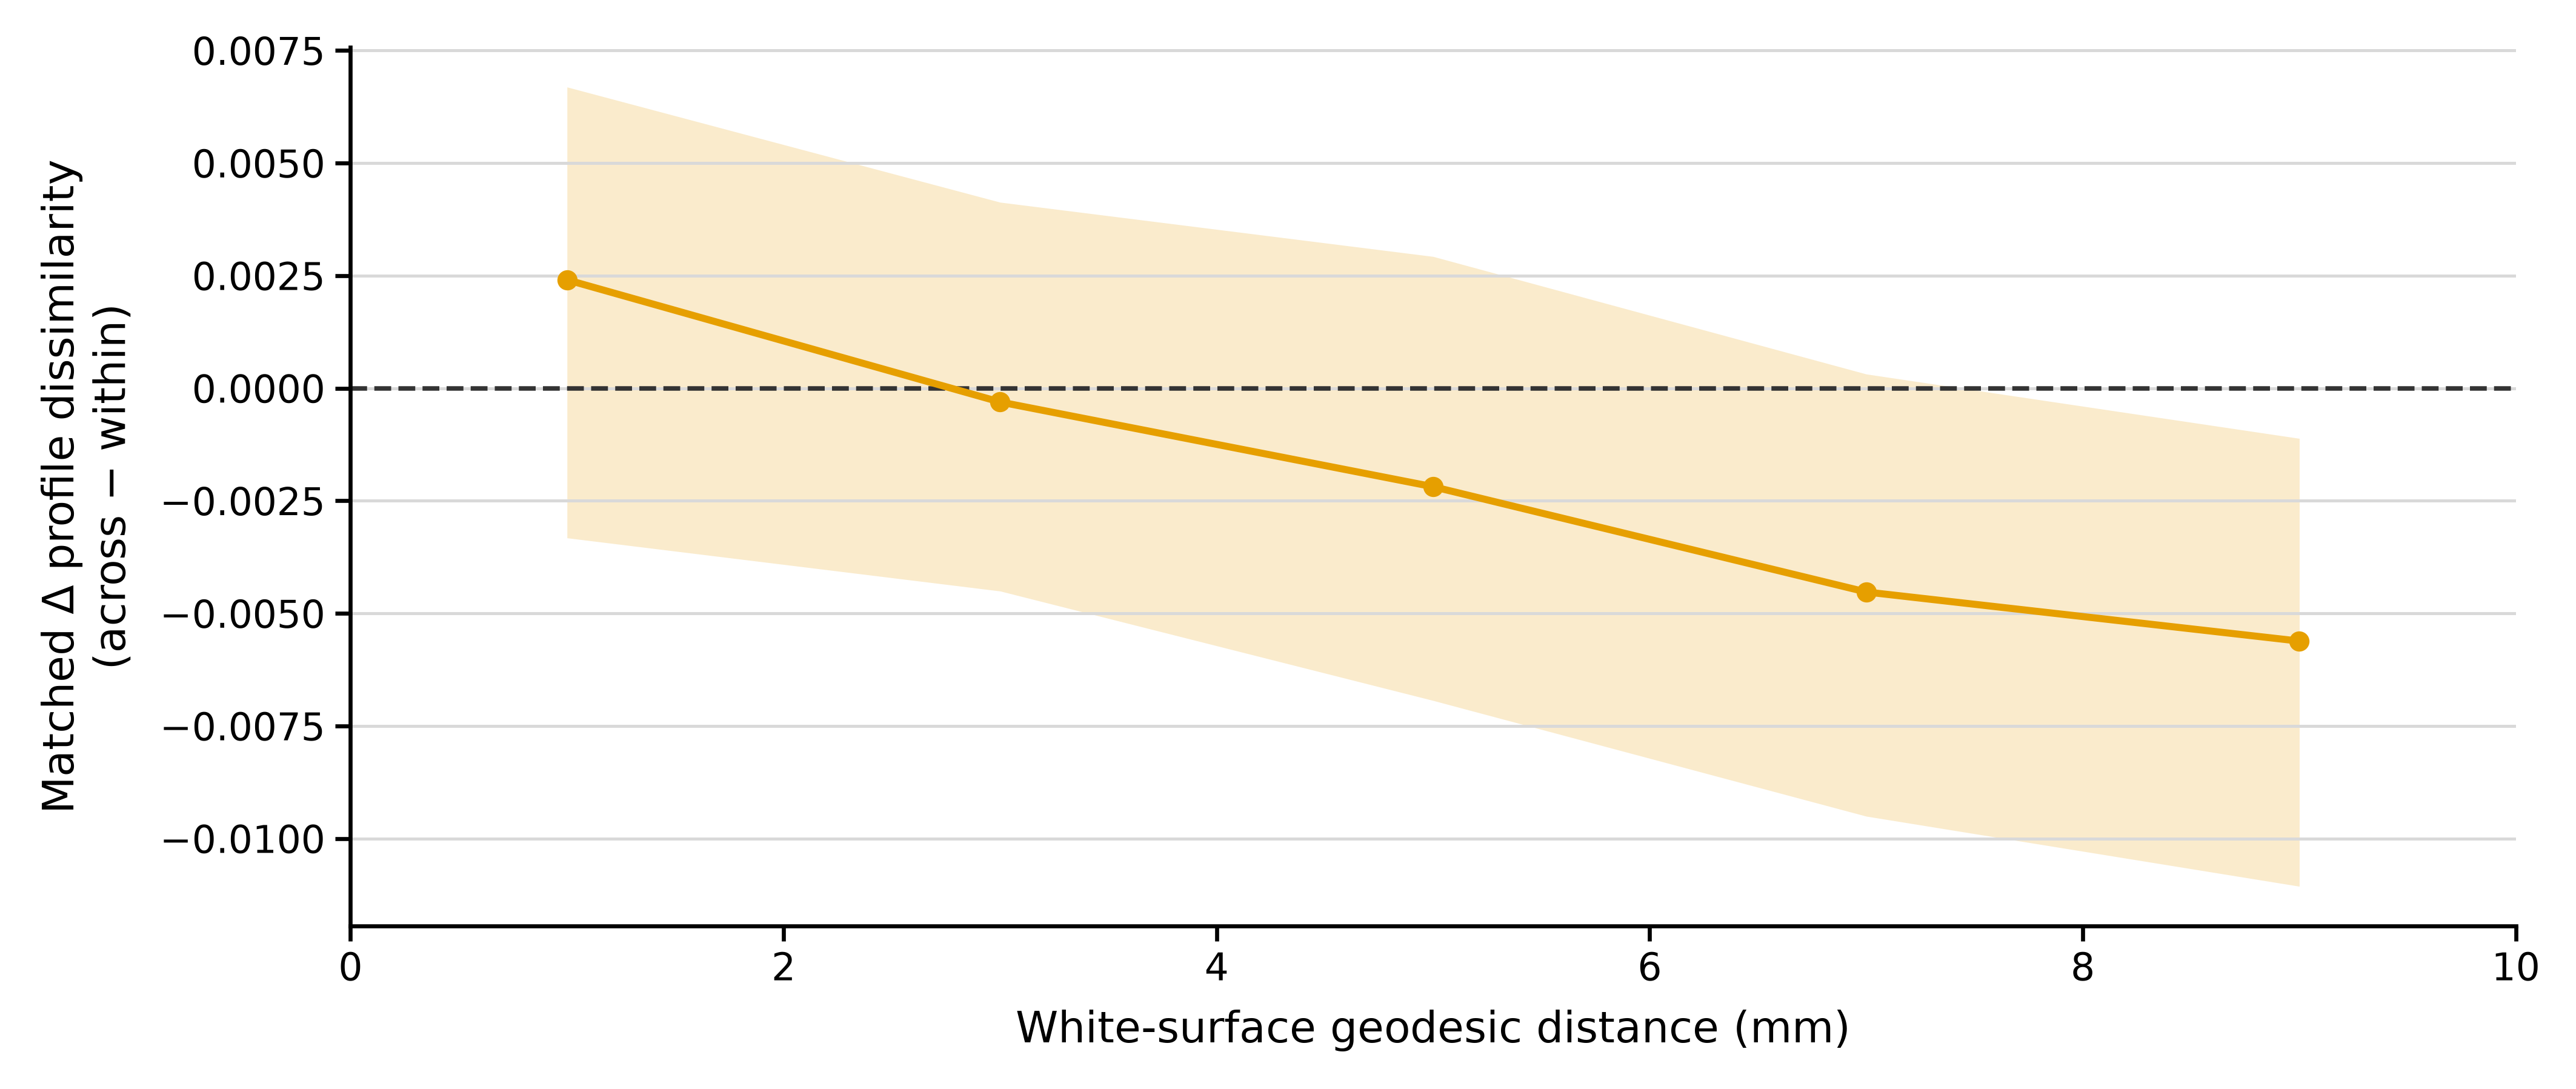

In [5]:
PART = ROOT / 'boundary_matched/formal/cohort'
display(pd.read_csv(PART / 'figure4D_0_10_group_summary.csv'))
display(pd.read_csv(PART / 'figure4D_group_summary.csv'))
display(Image(filename=str(PART / 'Figure4D_boundary_matched_0_10.png')))


## Provenance and scope

Reaggregation script: `analysis_results/figure4/scripts/refresh_registration_qc_cohort.py`. Cohort audit: `analysis_results/figure4/outputs/registration_qc_pass_320/cohort_refresh_report.json`. No historical 325-subject result files are overwritten. Supplemental and region-level notebooks retain their historical cohorts until explicitly refreshed; they should not be mixed with the active 320-subject primary analysis.